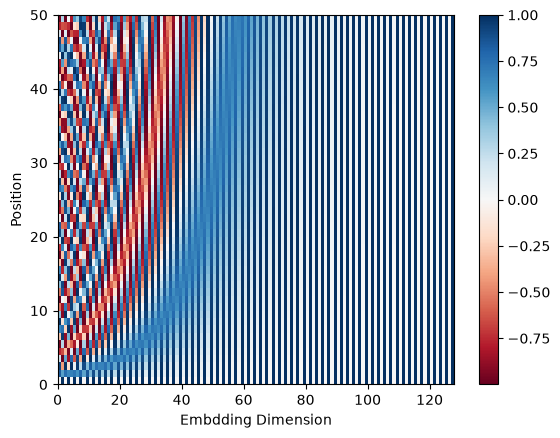

In [ ]:
import math
import torch
from torch import nn
import matplotlib.pyplot as plt

class PositionalEncoding(nn.Module):
	def __init__(self, d_model, max_len, dropout = 0.1):
		super().__init__()
		self.dropout = nn.Dropout(p = dropout)

		position = torch.arange(max_len).unsqueeze(1)
		div_term = torch.exp(
			torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
		)

		pe = torch.zeros(max_len, 1, d_model)
		pe[:, 0, 0::2] = torch.sin(position * div_term)
		pe[:, 0, 1::2] = torch.cos(position * div_term)
		self.register_buffer("pe", pe)


	def forward(self, x):
		x = x + self.pe[: x.size(0)]
		return self.dropout(x)

encoding = PositionalEncoding(d_model = 128, max_len = 50)

plt.pcolormesh(encoding.pe.numpy().squeeze(), cmap = "RdBu")
plt.xlabel("Embdding Dimension")
plt.xlim((0, 128))
plt.ylabel("Position")
plt.colorbar()
plt.show()

In [6]:
import torch
from torchtext.datasets import Multi30k
from torchtext.data.utils import get_tokenizer
from torchtext.vocab import build_vocab_from_iterator

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device) 

cuda


In [7]:
# 종합 테스트
import torch
import torchtext

print("torch:", torch.__version__)
print("torchtext:", torchtext.__version__)
print("device:", device)

# 데이터 하나 로드
from torchtext.datasets import Multi30k
train_iter = Multi30k(split='train', language_pair=('de', 'en'))
first = next(iter(train_iter))
print("데이터 샘플:", first)

torch: 2.11.0+cu128
torchtext: 0.18.0+compat
device: cuda


데이터 샘플: ('Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.', 'Two young, White males are outside near many bushes.')


In [13]:
# import sys

# !{sys.executable} -m spacy download de_core_news_sm
# !{sys.executable} -m spacy download en_core_web_sm

In [ ]:
def generate_tokens(text_iter, language):
	language_index = {SRC_LANG: 0, TGT_LANG: 1}

	for text in text_iter:
		yield token_transform[language](text[language_index[language]])

SRC_LANG = 'de'
TGT_LANG = 'en'
UNK_IDX, PAD_IDX, BOS_IDX, EOS_IDX = 0, 1, 2, 3
special_symbols = ['<unk>', '<pad>', '<bos>', '<eos>']

token_transform = {
	SRC_LANG : get_tokenizer("spacy", language = "de_core_news_sm"),
	TGT_LANG : get_tokenizer("spacy", language = "en_core_web_sm"),
	}

print(token_transform)

{'de': <function get_tokenizer.<locals>.<lambda> at 0x000001E1399213A0>, 'en': <function get_tokenizer.<locals>.<lambda> at 0x000001E13B01B7E0>}


In [ ]:
vocab_transform = {}
for language in [SRC_LANG, TGT_LANG]:
	train_iter = Multi30k(split="train", language_pair = {SRC_LANG, TGT_LANG})
	vocab_transform[language] = build_vocab_from_iterator(
		generate_tokens(train_iter, language),
		min_freq = 1,
		specials = special_symbols,
		special_first = True
	)

for language in [SRC_LANG, TGT_LANG]:
	vocab_transform[language].set_default_index(UNK_IDX)

print(vocab_transform)

{'de': <torchtext.vocab.Vocab object at 0x000001E13F67C0B0>, 'en': <torchtext.vocab.Vocab object at 0x000001E1411EC0B0>}


In [ ]:
import math
import torch
from torch import nn

class PositionalEncoding(nn.Module):
	def __init__(self, d_model, max_len, dropout = 0.1):
		super().__init__()
		self.dropout = nn.Dropout(p = dropout)

		position = torch.arange(max_len).unsqueeze(1)
		div_term = torch.exp(
			torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
		)

		pe = torch.zeros(max_len, 1, d_model)
		pe[:, 0, 0::2] = torch.sin(position * div_term)
		pe[:, 0, 1::2] = torch.cos(position * div_term)
		self.register_buffer("pe", pe)


	def forward(self, x):
		x = x + self.pe[: x.size(0)]
		return self.dropout(x)

In [ ]:
class TokenEmbedding(nn.Module):
	def __init__(self, vocab_size, emb_size):
		super().__init__()
		self.embedding = nn.Embedding(vocab_size, emb_size)
		self.emb_size = emb_size

	def forward(self, tokens):
		return self.embedding(tokens.long()) * math.sqrt(self.emb_size)

In [38]:
class Seq2SeqTransformer(nn.Module):
	def __init__(self,
			  	num_encoder_layers,
				num_decoder_layers,
				emb_size,
				max_len,
				nhead,
				src_vocab_size,
				tgt_vocab_size,
				dim_feedforward,
				dropout = 0.1):
		super().__init__()
		self.src_tok_emb = TokenEmbedding(src_vocab_size, emb_size)
		self.tgt_tok_emb = TokenEmbedding(tgt_vocab_size, emb_size)
		self.positional_encoding = PositionalEncoding(d_model = emb_size,
													max_len = max_len,
													dropout = dropout)
		self.transformer = nn.Transformer(d_model = emb_size,
								   nhead = nhead,
								   num_encoder_layers = num_encoder_layers,
								   num_decoder_layers = num_decoder_layers,
								   dim_feedforward = dim_feedforward,
								   dropout = dropout)
		
		self.generator = nn.Linear(emb_size, tgt_vocab_size)

	def forward(self,
			 src,
			 tgt,
			 src_mask,
			 tgt_mask,
			 src_padding_mask,
			 tgt_padding_mask,
			 memory_key_padding_mask):
		
		src_emb = self.positional_encoding(self.src_tok_emb(src))
		tgt_emb = self.positional_encoding(self.tgt_tok_emb(tgt))
		outs = self.transformer(src = src_emb,
						  tgt = tgt_emb,
						  src_mask = src_mask,
						  tgt_mask = tgt_mask,
						  memory_mask = None,
						  src_key_padding_mask = src_padding_mask,
						  tgt_key_padding_mask = tgt_padding_mask,
						  memory_key_padding_mask = memory_key_padding_mask
						  )
		return self.generator(outs)

	def encode(self, src, src_mask):
		return self.transformer.encoder(
			self.positional_encoding(self.src_tok_emb(src)), src_mask
		)

	def decode(self, tgt, memory, tgt_mask):
		return self.transformer.decoder(
			self.positional_encoding(self.tgt_tok_emb(tgt)), memory, tgt_mask
		)
		

In [39]:
from torch import optim

BATCH_SIZE = 128

model = Seq2SeqTransformer(
	num_encoder_layers = 3,
	num_decoder_layers = 3,
	emb_size = 512,
	max_len = 512,
	nhead = 8,
	src_vocab_size = len(vocab_transform[SRC_LANG]),
	tgt_vocab_size = len(vocab_transform[TGT_LANG]),
	dim_feedforward = 512
).to(device)

criterion = nn.CrossEntropyLoss(ignore_index = PAD_IDX).to(device)
optimizer = optim.Adam(model.parameters())

for main_name, main_module, in model.named_children():
	print(main_name)
	for sub_name, sub_module in main_module.named_children():
		print("-", sub_name)
		for ssub_name, ssub_module in sub_module.named_children():
			print("--", ssub_name)
			for sssub_name, sssubmodule in ssub_module.named_children():
				print("---", ssub_name)

src_tok_emb
- embedding
tgt_tok_emb
- embedding
positional_encoding
- dropout
transformer
- encoder
-- layers
--- layers
--- layers
--- layers
-- norm
- decoder
-- layers
--- layers
--- layers
--- layers
-- norm
generator


In [40]:
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence


def sequential_transforms(*transforms):
	def func(txt_input):
		for transform in transforms:
			txt_input = transform(txt_input)
		return txt_input
	return func

def input_transform(token_ids):
	return torch.cat(
		(torch.tensor([BOS_IDX]), torch.tensor(token_ids), torch.tensor([EOS_IDX]))
	)

def collator(batch):
	src_batch, tgt_batch = [], []
	for src_sample, tgt_sample in batch:
		src_batch.append(text_transform[SRC_LANG](src_sample.rstrip("\n")))
		tgt_batch.append(text_transform[TGT_LANG](tgt_sample.rstrip("\n")))

	src_batch = pad_sequence(src_batch, padding_value=PAD_IDX)
	tgt_batch = pad_sequence(tgt_batch, padding_value=PAD_IDX)
	return src_batch, tgt_batch


text_transform = {}
for language in [SRC_LANG, TGT_LANG]:
	text_transform[language] = sequential_transforms(
		token_transform[language], vocab_transform[language], input_transform
	)

data_iter = Multi30k(
	split="valid",
	language_pair=(SRC_LANG, TGT_LANG)
)

data_list = list(data_iter)

dataloader = DataLoader(
	data_list,
	batch_size=BATCH_SIZE,
	collate_fn=collator
)

source_tensor, target_tensor = next(iter(dataloader))

print("(source, target):")
print(data_list[0])

print("source_batch:", source_tensor.shape)
print(source_tensor)

print("target_batch:", target_tensor.shape)
print(target_tensor)

(source, target):
('Eine Gruppe von Männern lädt Baumwolle auf einen Lastwagen', 'A group of men are loading cotton onto a truck')
source_batch: torch.Size([35, 128])
tensor([[   2,    2,    2,  ...,    2,    2,    2],
        [  14,    5,    5,  ...,    5,   21,    5],
        [  38,   12,   35,  ...,   12, 1750,   69],
        ...,
        [   1,    1,    1,  ...,    1,    1,    1],
        [   1,    1,    1,  ...,    1,    1,    1],
        [   1,    1,    1,  ...,    1,    1,    1]])
target_batch: torch.Size([30, 128])
tensor([[   2,    2,    2,  ...,    2,    2,    2],
        [   6,    6,    6,  ...,  250,   19,    6],
        [  39,   12,   35,  ...,   12, 3254,   61],
        ...,
        [   1,    1,    1,  ...,    1,    1,    1],
        [   1,    1,    1,  ...,    1,    1,    1],
        [   1,    1,    1,  ...,    1,    1,    1]])


In [41]:
def generate_square_subsequent_mask(s):
	mask = (torch.triu(torch.ones((s, s), device=device)) == 1).transpose(0, 1)
	mask = (
		mask.float()
		.masked_fill(mask == 0, float("-inf"))
		.masked_fill(mask == 1, float(0.0))
	)
	return mask


def create_mask(src, tgt):
	src_seq_len = src.shape[0]
	tgt_seq_len = tgt.shape[0]

	tgt_mask = generate_square_subsequent_mask(tgt_seq_len)
	src_mask = torch.zeros((src_seq_len, src_seq_len), device=device)

	src_padding_mask = (src == PAD_IDX).transpose(0, 1)
	tgt_padding_mask = (tgt == PAD_IDX).transpose(0, 1)
	return src_mask, tgt_mask, src_padding_mask, tgt_padding_mask


target_input = target_tensor[:-1, :]
target_out = target_tensor[1:, :]

source_mask, target_mask, source_padding_mask, target_padding_mask = create_mask(
	source_tensor, target_input
)

print("source_mask:", source_mask.shape)
print(source_mask)
print("target_mask:", target_mask.shape)
print(target_mask)
print("source_padding_mask:", source_padding_mask.shape)
print(source_padding_mask)
print("target_padding_mask:", target_padding_mask.shape)
print(target_padding_mask)

source_mask: torch.Size([35, 35])
tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]], device='cuda:0')
target_mask: torch.Size([29, 29])
tensor([[0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf,
         -inf, -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf,
         -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf,
         -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -in

In [42]:
def run(model, optimizer, criterion, split):

    is_train = split == "train"

    # train / eval 모드 설정
    if is_train:
        model.train()
    else:
        model.eval()

    # Multi30k는 generator라서 list로 변환
    data_iter = Multi30k(
        split=split,
        language_pair=(SRC_LANG, TGT_LANG)
    )

    data_list = list(data_iter)

    # 반드시 data_list를 DataLoader에 넣기
    dataloader = DataLoader(
        data_list,
        batch_size=BATCH_SIZE,
        collate_fn=collator,
        shuffle=is_train
    )

    losses = 0.0

    for source_batch, target_batch in dataloader:

        source_batch = source_batch.to(device)
        target_batch = target_batch.to(device)

        # decoder 입력
        target_input = target_batch[:-1, :]

        # 정답
        target_output = target_batch[1:, :]

        # mask 생성
        (
            src_mask,
            tgt_mask,
            src_padding_mask,
            tgt_padding_mask
        ) = create_mask(
            source_batch,
            target_input
        )

        # validation에서는 gradient 계산 안 함
        with torch.set_grad_enabled(is_train):

            logits = model(
                src=source_batch,
                tgt=target_input,
                src_mask=src_mask,
                tgt_mask=tgt_mask,
                src_padding_mask=src_padding_mask,
                tgt_padding_mask=tgt_padding_mask,
                memory_key_padding_mask=src_padding_mask
            )

            loss = criterion(
                logits.reshape(-1, logits.shape[-1]),
                target_output.reshape(-1)
            )

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        losses += loss.item()

    return losses / len(dataloader)

In [43]:
for epoch in range(5):
	train_loss = run(model, optimizer, criterion, "train")
	val_loss = run(model, optimizer, criterion, "valid")
	print(epoch+1, train_loss, val_loss)

c:\Users\KDS-30\Desktop\class\10_LLM_CV\.venv-cuda\Lib\site-packages\torch\nn\modules\transformer.py:431: UserWarning: Support for mismatched src_key_padding_mask and mask is deprecated. Use same type for both instead.
  src_key_padding_mask = F._canonical_mask(
c:\Users\KDS-30\Desktop\class\10_LLM_CV\.venv-cuda\Lib\site-packages\torch\nn\modules\activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


1 4.563666052755281 3.8023630380630493
2 3.634507161405118 3.4730542302131653
3 3.3807211247834865 3.402942806482315
4 3.2185134173489875 3.327875256538391
5 3.06849090538361 3.2761144936084747


In [44]:
def greedy_decode(model, source_tensor, source_mask, max_len, start_symbol):
    source_tensor = source_tensor.to(device)
    source_mask = source_mask.to(device)

    memory = model.encode(source_tensor, source_mask)
    ys = torch.ones(1, 1).fill_(start_symbol).type(torch.long).to(device)
    for i in range(max_len - 1):
        memory = memory.to(device)
        target_mask = generate_square_subsequent_mask(ys.size(0))
        target_mask = target_mask.type(torch.bool).to(device)

        out = model.decode(ys, memory, target_mask)
        out = out.transpose(0, 1)
        prob = model.generator(out[:, -1])
        _, next_word = torch.max(prob, dim=1)
        next_word = next_word.item()

        ys = torch.cat(
            [ys, torch.ones(1, 1).type_as(source_tensor.data).fill_(next_word)], dim=0
        )
        if next_word == EOS_IDX:
            break
    return ys


def translate(model, source_sentence):
    model.eval()
    source_tensor = text_transform[SRC_LANG](source_sentence).view(-1, 1)
    num_tokens = source_tensor.shape[0]
    src_mask = (torch.zeros(num_tokens, num_tokens)).type(torch.bool)
    tgt_tokens = greedy_decode(
        model, source_tensor, src_mask, max_len=num_tokens + 5, start_symbol=BOS_IDX
    ).flatten()
    output = vocab_transform[TGT_LANG].lookup_tokens(list(tgt_tokens.cpu().numpy()))[1:-1]
    return " ".join(output)


output_oov = translate(model, "Eine Gruppe von Menschen steht vor einem Iglu .")
output = translate(model, "Eine Gruppe von Menschen steht vor einem Gebäude .")
print(output_oov)
print(output)

A group of people are standing in the middle of a building .
A group of people are standing in the middle of a building .
